In [2]:
import os
print(os.getcwd())

/drive


In [23]:
with open("mwgc.dat", "r", encoding="utf-8", errors="replace") as file:
    lines = file.readlines()

print("Number of lines:", len(lines))
print("".join(lines[:162]))

Number of lines: 162
 

   ID       [Fe/H] wt  E(B-V) V_HB (m-M)V V_t   M_V,t   U-B   B-V   V-R   V-I  spt   ellip

 NGC 104     -0.72 10   0.04 14.06 13.37  3.95  -9.42   0.37  0.88  0.53  1.14  G4    0.09
 NGC 288     -1.32  3   0.03 15.44 14.84  8.09  -6.75   0.08  0.65  0.45  0.94
 NGC 362     -1.26  5   0.05 15.44 14.83  6.40  -8.43   0.16  0.77  0.49  1.01  F9    0.01
 Whiting 1   -0.70  1   0.03 18.18 17.49 15.03  -2.46                         
 NGC 1261    -1.27  3   0.01 16.70 16.09  8.29  -7.80   0.13  0.72  0.45  0.93  F7    0.07
 Pal 1       -0.65  2   0.15 16.40 15.70 13.18  -2.52         0.96                    0.22
 AM 1        -1.70  2   0.00 21.00 20.45 15.72  -4.73         0.72            
 Eridanus    -1.43  4   0.02 20.42 19.83 14.70  -5.13         0.79            
 Pal 2       -1.42  1   1.24 21.60 21.01 13.04  -7.97   1.83  2.08        2.65        0.05
 NGC 1851    -1.18  9   0.02 16.09 15.47  7.14  -8.33   0.17  0.76  0.49  1.01  F7    0.05
 NGC 1904    -1.60  6 

In [24]:
import urllib.request

url = "https://physics.mcmaster.ca/~harris/mwgc.dat"

try:
    with urllib.request.urlopen(url, timeout=20) as response:
        print("Connection successful!")
        print(response.status)
except Exception as e:
    print("Connection failed:", repr(e))

Connection failed: URLError(OSError(23, 'Host is unreachable'))


In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the table into a Pandas DataFrame
# Note: Since headers and formatting might vary slightly, using sep=r'\s+' handles space delimiters
df = pd.read_csv("mwgc.dat", sep=r'\s+', comment='#', engine='python')

# Display the first few rows and column names to confirm
print(df.columns)
print(df.head())

Index(['ID', '[Fe/H]', 'wt', 'E(B-V)', 'V_HB', '(m-M)V', 'V_t', 'M_V,t', 'U-B',
       'B-V', 'V-R', 'V-I', 'spt', 'ellip'],
      dtype='str')
             ID  [Fe/H]    wt  E(B-V)   V_HB  (m-M)V    V_t  M_V,t   U-B  \
NGC       104.0   -0.72  10.0    0.04  14.06   13.37   3.95  -9.42  0.37   
NGC       288.0   -1.32   3.0    0.03  15.44   14.84   8.09  -6.75  0.08   
NGC       362.0   -1.26   5.0    0.05  15.44   14.83   6.40  -8.43  0.16   
Whiting     1.0   -0.70   1.0    0.03  18.18   17.49  15.03  -2.46   NaN   
NGC      1261.0   -1.27   3.0    0.01  16.70   16.09   8.29  -7.80  0.13   

          B-V   V-R   V-I  spt  ellip  
NGC      0.88  0.53  1.14   G4   0.09  
NGC      0.65  0.45  0.94  NaN    NaN  
NGC      0.77  0.49  1.01   F9   0.01  
Whiting   NaN   NaN   NaN  NaN    NaN  
NGC      0.72  0.45  0.93   F7   0.07  


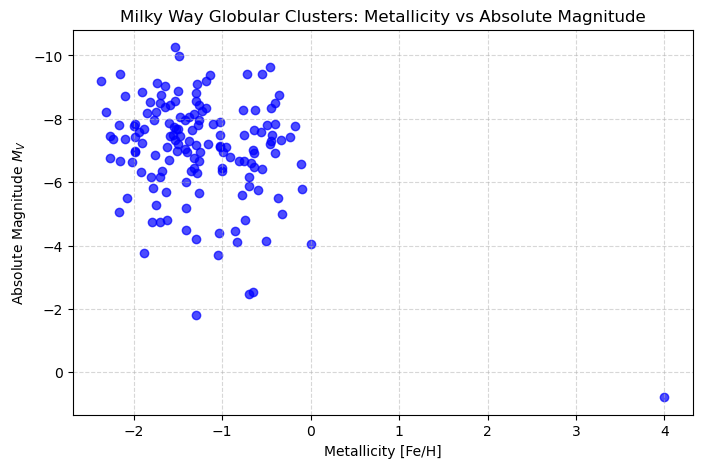

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.scatter(df['[Fe/H]'], df['M_V,t'], color='blue', alpha=0.7)

# In astronomy, brighter magnitudes are more negative, so invert the y-axis
plt.gca().invert_yaxis()

plt.xlabel('Metallicity [Fe/H]')
plt.ylabel('Absolute Magnitude $M_V$')
plt.title('Milky Way Globular Clusters: Metallicity vs Absolute Magnitude')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

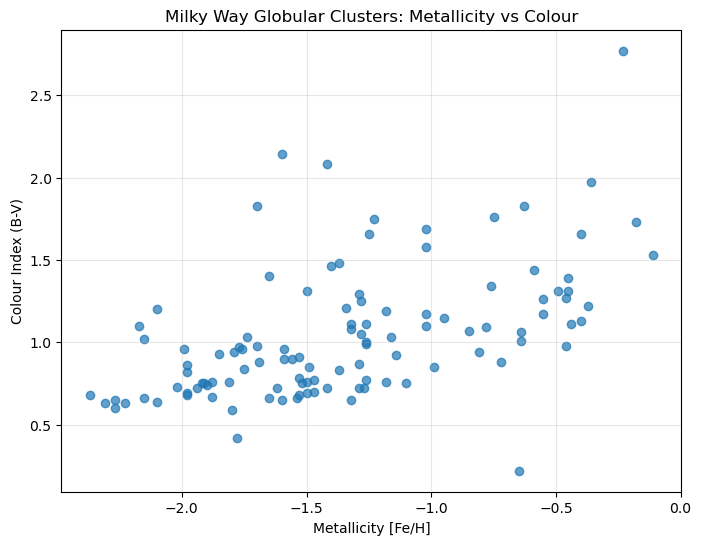

In [27]:

plt.figure(figsize=(8, 6))

plt.scatter(df["[Fe/H]"], df["B-V"], alpha=0.7)

plt.xlabel("Metallicity [Fe/H]")
plt.ylabel("Colour Index (B-V)")
plt.title("Milky Way Globular Clusters: Metallicity vs Colour")
plt.grid(True, alpha=0.3)

plt.show()

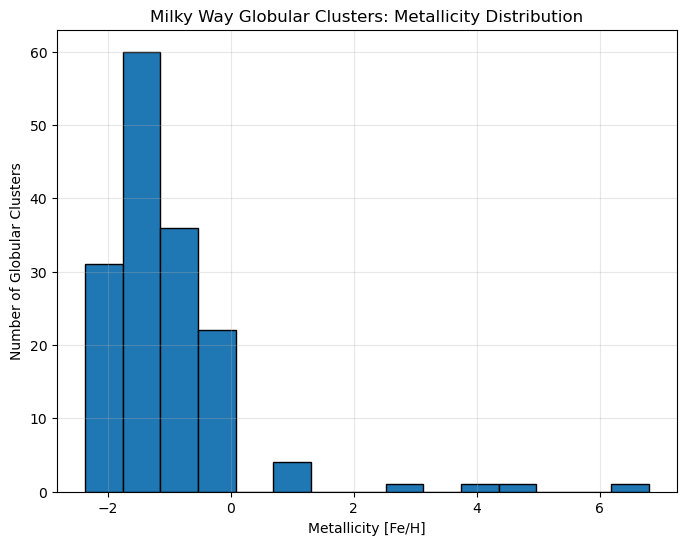

In [28]:

plt.figure(figsize=(8, 6))

plt.hist(df["[Fe/H]"].dropna(), bins=15, edgecolor="black")

plt.xlabel("Metallicity [Fe/H]")
plt.ylabel("Number of Globular Clusters")
plt.title("Milky Way Globular Clusters: Metallicity Distribution")
plt.grid(True, alpha=0.3)

plt.show()

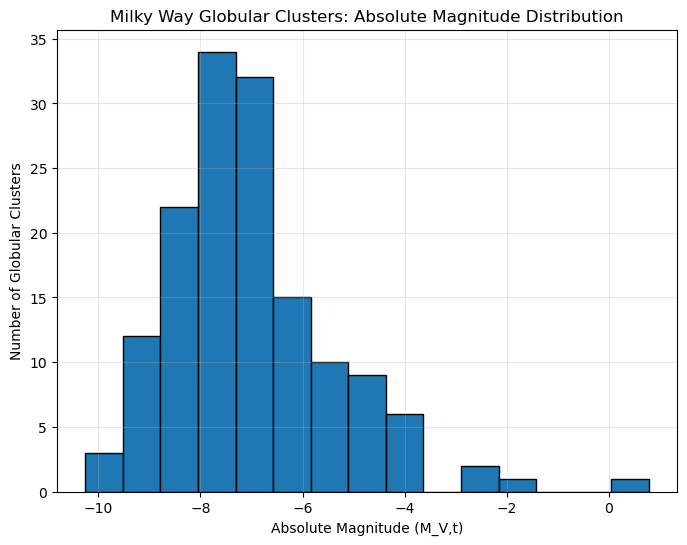

In [29]:

plt.figure(figsize=(8, 6))

plt.hist(df["M_V,t"].dropna(), bins=15, edgecolor="black")

plt.xlabel("Absolute Magnitude (M_V,t)")
plt.ylabel("Number of Globular Clusters")
plt.title("Milky Way Globular Clusters: Absolute Magnitude Distribution")
plt.grid(True, alpha=0.3)

plt.show()